# DSC8307 – Assignment 1
## Data Mining, Modeling and Analytics

**Student Name:** Tayebwa Yonah  
**Registration Number:** M24M19/001  
**Student Number:** B28697  
**Programme:** MSc Data Science and Analytics  
**University:** Uganda Christian University  
**Academic Year:** 2026

# Project 1 — Bank Marketing: Term-deposit Subscription
**DSC8307 | Data Mining, Modeling and Analytics | Advent 2026**

**Research question:** Can pre-call customer, campaign-history, and economic characteristics predict subscription, and what decision threshold best balances unnecessary calls against missed subscribers?

**Method:** stratified 60/20/20 train/validation/test split; preprocessing learned only on training data; three pre-specified approaches (logistic regression, random forest, histogram gradient boosting); selection on validation average precision (AP); threshold tuned only on validation data; untouched test evaluation. Random seed fixed at 42.

**Important leakage restriction:** `duration` is the duration of the *current* call, known only after making that call. It is excluded because the intended application is selecting whom to call beforehand. All findings are observational and subject to temporal and campaign shift.

In [16]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix, PrecisionRecallDisplay, RocCurveDisplay, classification_report)
from sklearn.dummy import DummyClassifier
SEED=42
path=Path('bank-additional-full.csv')
if not path.exists(): path=Path('..')/path
raw=pd.read_csv(path,sep=';')
print('Shape:',raw.shape,'Duplicate rows:',raw.duplicated().sum())
display(raw.head(),raw.describe(include='all').T)
print('Missing (NaN):',raw.isna().sum().sort_values(ascending=False).head(10).to_dict())
print('Unknown-coded categories:',{c:int((raw[c]=='unknown').sum()) for c in raw.select_dtypes('object') if (raw[c]=='unknown').any()})
print('Target distribution:',raw.y.value_counts().to_dict())

Shape: (41188, 21) Duplicate rows: 12


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing (NaN): {'age': 0, 'campaign': 0, 'nr.employed': 0, 'euribor3m': 0, 'cons.conf.idx': 0, 'cons.price.idx': 0, 'emp.var.rate': 0, 'poutcome': 0, 'previous': 0, 'pdays': 0}
Unknown-coded categories: {'job': 330, 'marital': 80, 'education': 1731, 'default': 8597, 'housing': 990, 'loan': 990}
Target distribution: {'no': 36548, 'yes': 4640}


/var/folders/p2/v62ptt3d26n10mknz1nxhzzc0000gn/T/ipykernel_12464/903841155.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print('Unknown-coded categories:',{c:int((raw[c]=='unknown').sum()) for c in raw.select_dtypes('object') if (raw[c]=='unknown').any()})


## Exploration and data preparation
The target is imbalanced, so accuracy alone is misleading. `unknown` is a documented categorical level rather than a numeric missing value; retain it as a potentially informative category. Do not delete duplicates indiscriminately: identical profiles can correspond to distinct contacts. Treat `pdays=999` as a documented sentinel for no prior contact; retain it as a numeric indicator rather than treating it as missing. Exclude `duration` to avoid post-call leakage. The data are collected over time, so a random stratified holdout measures within-dataset generalization rather than deployment across future months; a later chronological validation would be preferable with true contact timestamps.

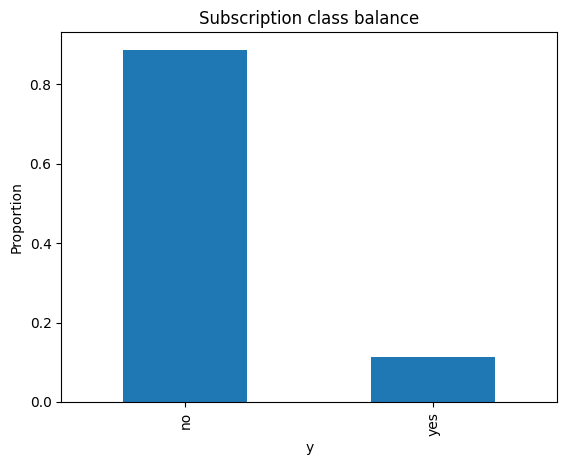

Splits: 24712 8238 8238
Numeric: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [17]:
raw.y.value_counts(normalize=True).rename('share').plot.bar(title='Subscription class balance');plt.ylabel('Proportion');plt.show()
X=raw.drop(columns=['y','duration']); y=(raw.y=='yes').astype(int)
X_trainval,X_test,y_trainval,y_test=train_test_split(X,y,test_size=.2,stratify=y,random_state=SEED)
X_train,X_val,y_train,y_val=train_test_split(X_trainval,y_trainval,test_size=.25,stratify=y_trainval,random_state=SEED)
num=X.select_dtypes(include=np.number).columns.tolist(); cat=X.select_dtypes(exclude=np.number).columns.tolist()
pre=ColumnTransformer([('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('categorical',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat)],sparse_threshold=0)
print('Splits:',len(X_train),len(X_val),len(X_test));print('Numeric:',num);print('Categorical:',cat)

## Models, metrics and model selection
**Rank by validation AP** (area under the precision–recall curve), because the positive class is relatively rare. Report ROC-AUC for ranking discrimination and precision/recall for operational impact. The majority-class baseline predicts no subscriptions; its recall is zero. Logistic regression is a transparent regularized linear benchmark; random forest captures interactions and nonlinearity; histogram gradient boosting offers efficient nonlinear boosted trees. Hyperparameters are fixed before the holdout comparison to avoid excessive tuning.

,model,validation_AP,validation_ROC_AUC,precision_at_0.5,recall_at_0.5
0,Random forest,0.466778,0.798802,0.652542,0.248922
1,Gradient boosting,0.465771,0.804618,0.634615,0.248922
2,Logistic regression,0.441423,0.797070,0.350211,0.626078


Majority baseline accuracy: 0.8873512988589464 recall: 0.0
Random-ranking AP reference: 0.1126


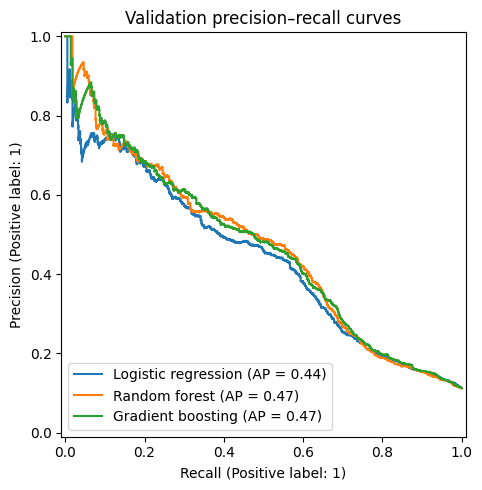

In [13]:
baseline=DummyClassifier(strategy='most_frequent').fit(X_train,y_train)
models={
 'Logistic regression':Pipeline([('prep',pre),('model',LogisticRegression(max_iter=1500,class_weight='balanced',random_state=SEED))]),
 'Random forest':Pipeline([('prep',pre),('model',RandomForestClassifier(n_estimators=160,min_samples_leaf=5,n_jobs=-1,random_state=SEED))]),
 'Gradient boosting':Pipeline([('prep',pre),('model',HistGradientBoostingClassifier(max_iter=150,learning_rate=.07,l2_regularization=1.0,random_state=SEED))])}
rows=[]; fitted={}
for name,model in models.items():
 model.fit(X_train,y_train); fitted[name]=model
 p=model.predict_proba(X_val)[:,1]
 rows.append({'model':name,'validation_AP':average_precision_score(y_val,p),'validation_ROC_AUC':roc_auc_score(y_val,p),'precision_at_0.5':precision_score(y_val,p>=.5,zero_division=0),'recall_at_0.5':recall_score(y_val,p>=.5,zero_division=0)})
results=pd.DataFrame(rows).sort_values('validation_AP',ascending=False).reset_index(drop=True)
display(results)
print('Majority baseline accuracy:',baseline.score(X_val,y_val),'recall:',recall_score(y_val,baseline.predict(X_val),zero_division=0))
print('Random-ranking AP reference:',round(y_val.mean(),4))
fig,ax=plt.subplots(figsize=(7,5))
for name,m in fitted.items(): PrecisionRecallDisplay.from_predictions(y_val,m.predict_proba(X_val)[:,1],name=name,ax=ax)
plt.title('Validation precision–recall curves');plt.tight_layout();plt.show()

## Operational threshold and sensitivity
Without verified business costs, no threshold is universally optimal. We use an explicit, **illustrative** value model: each successful subscriber reached is worth 10 units and each call costs 1 unit. Expected incremental net value for a set of calls is `10 × true positives − 1 × number called` (this assumes the label is a proxy for conversion if contacted; it does **not** estimate causal uplift). Choose the threshold on validation data only. Compare it with 0.5 and report sensitivity to assumed value/cost ratios of 5, 10, and 20. Lower thresholds tend to increase calls and recall, but also unnecessary calls; higher thresholds miss more subscribers.

Selected model: Random forest threshold: 0.12


,threshold,calls,true_positives,unnecessary_calls,missed_subscribers,precision,recall,illustrative_net_value
0,0.12,1671,601,1070,327,0.359665,0.647629,4339
1,0.50,354,231,123,697,0.652542,0.248922,1956


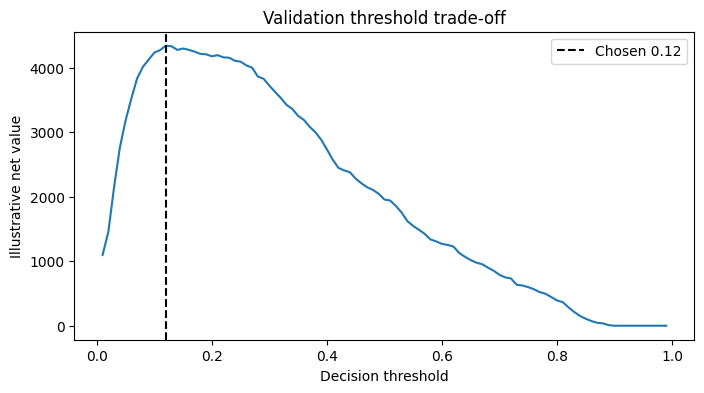

Value/call-cost ratio 5: best threshold=0.23, calls=1187, missed=394
Value/call-cost ratio 10: best threshold=0.12, calls=1671, missed=327
Value/call-cost ratio 20: best threshold=0.04, calls=5720, missed=80


In [14]:
best_name=results.loc[0,'model'];best=fitted[best_name]
pval=best.predict_proba(X_val)[:,1]
def score_threshold(y_true,prob,threshold,value=10,cost=1):
 chosen=prob>=threshold;tp=int(((y_true==1)&chosen).sum());fp=int(((y_true==0)&chosen).sum());fn=int(((y_true==1)&(~chosen)).sum())
 return {'threshold':float(threshold),'calls':int(chosen.sum()),'true_positives':tp,'unnecessary_calls':fp,'missed_subscribers':fn,'precision':precision_score(y_true,chosen,zero_division=0),'recall':recall_score(y_true,chosen,zero_division=0),'illustrative_net_value':value*tp-cost*int(chosen.sum())}
thresholds=np.linspace(.01,.99,99)
scans=pd.DataFrame([score_threshold(y_val,pval,t) for t in thresholds])
selected=float(scans.sort_values(['illustrative_net_value','calls'],ascending=[False,True]).iloc[0]['threshold'])
print('Selected model:',best_name,'threshold:',selected)
display(pd.DataFrame([score_threshold(y_val,pval,t) for t in [selected,.5]]))
fig,ax=plt.subplots(figsize=(8,4));ax.plot(scans.threshold,scans.illustrative_net_value);ax.axvline(selected,color='black',ls='--',label=f'Chosen {selected:.2f}');ax.set(xlabel='Decision threshold',ylabel='Illustrative net value',title='Validation threshold trade-off');ax.legend();plt.show()
for value in [5,10,20]:
 s=pd.DataFrame([score_threshold(y_val,pval,t,value=value) for t in thresholds]);r=s.loc[s.illustrative_net_value.idxmax()]
 print(f'Value/call-cost ratio {value}: best threshold={r.threshold:.2f}, calls={int(r.calls)}, missed={int(r.missed_subscribers)}')

## Untouched test-set evaluation
The model and threshold were chosen using validation data. Evaluate exactly once on the held-out test set. Because training used class weighting for logistic regression and no probability calibration, the illustrative cost rule is evaluated empirically on validation, not inferred from a calibrated 0.1 probability cutoff. For production, validate probability calibration, actual contact costs, temporal stability, consent, and fairness before deployment.

Final test AP: 0.4841 ROC-AUC: 0.8089


,threshold,calls,true_positives,unnecessary_calls,missed_subscribers,precision,recall,illustrative_net_value
0,0.12,1643,612,1031,316,0.372489,0.659483,4477
1,0.50,348,238,110,690,0.683908,0.256466,2032


Confusion matrix at selected threshold (TN,FP / FN,TP):
 [[6279 1031]
 [ 316  612]]
              precision    recall  f1-score   support

           0       0.95      0.86      0.90      7310
           1       0.37      0.66      0.48       928

    accuracy                           0.84      8238
   macro avg       0.66      0.76      0.69      8238
weighted avg       0.89      0.84      0.86      8238



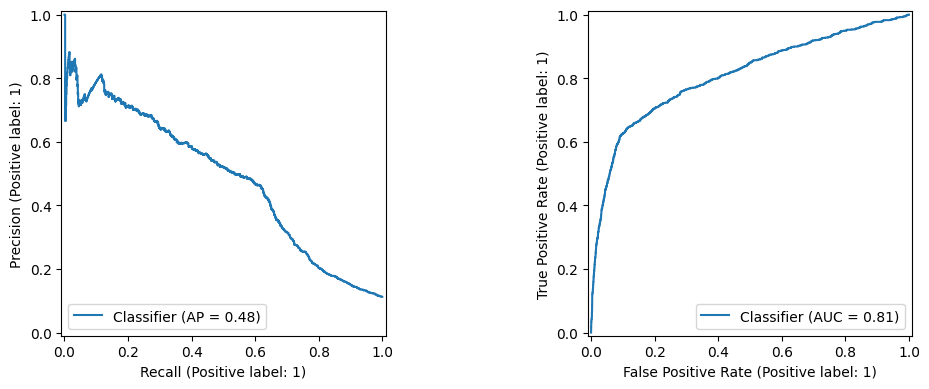

In [15]:
ptest=best.predict_proba(X_test)[:,1]
print('Final test AP:',round(average_precision_score(y_test,ptest),4),'ROC-AUC:',round(roc_auc_score(y_test,ptest),4))
display(pd.DataFrame([score_threshold(y_test,ptest,t) for t in [selected,.5]]))
print('Confusion matrix at selected threshold (TN,FP / FN,TP):\n',confusion_matrix(y_test,ptest>=selected))
print(classification_report(y_test,ptest>=selected,zero_division=0))
fig,axs=plt.subplots(1,2,figsize=(11,4));PrecisionRecallDisplay.from_predictions(y_test,ptest,ax=axs[0]);RocCurveDisplay.from_predictions(y_test,ptest,ax=axs[1]);plt.tight_layout();plt.show()